
# CS156 Session 17 — Filters, Convolutions, and Deep Learning

## Session Overview

This session focuses on how computers identify patterns in images using filters and convolutional neural networks (CNNs).

A CNN is a neural network that uses filters to learn visual patterns. These patterns can include edges, shapes, textures, and object parts.

In this notebook, I will use the raccoon image provided by SciPy to explore how filters work.

I will first extract an eye template and search for similar patterns in the original image. Then, I will apply vertical and horizontal Sobel filters to detect edges. Finally, I will combine their outputs to examine the overall edge strength.

### Learning Objectives

- Understanding convolution as local pattern matching.
- Explaining how filters detect image features.
- Comparing vertical and horizontal edge detection.
- Combining filter responses to measure edge strength.
- Connecting these operations to convolutional neural networks.



## Question 1 of 6 — CNN Intro (2)

### Understanding Convolutional Neural Networks

In my first prompt, I asked the LLM to explain how a CNN works. I focused on the roles of convolution, pooling, and fully connected layers.

In my second prompt, I requested a step-by-step explanation of convolution. I asked about kernels, stride, padding, and how filters create feature maps.

The responses helped me understand how CNNs process images. Earlier layers detect simpler patterns, while deeper layers can combine these into more complex features.

### Tied Weights and the Chain Rule

A CNN uses the same filter weights across different image locations. This is called weight sharing, or tied weights.

It reduces the number of parameters and allows the same pattern to be detected in different places.

The chain rule helps calculate how each weight affects the final prediction error. During backpropagation, gradients from all locations using the same weight are combined.

### My Evaluation

The LLM clearly explained weight sharing and backpropagation. However, the explanation could distinguish translation equivariance from translation invariance.

Convolution moves its output features when the input shifts. Pooling and later processing can make predictions less sensitive to these shifts.

The full LLM dialogue and original evaluation are included in my submitted pre-class workbook.



## Question 2 of 6 — Core Question: Convolutions

### Question

What is the correlation image? Why are there strong activations around the left eye and nose, even though the template comes from the right eye?

### Understanding the Task

Convolution can be understood as a local pattern-matching process.

We take a small part of an image, called a template, and compare it with different regions of a larger image.

The result is a feature map. Each value indicates how strongly the template matches the pixels around that location.

Strictly speaking, the SciPy function used here performs cross-correlation. Unlike mathematical convolution, cross-correlation does not flip the filter before applying it.

The calculation can be written as:

$$
R(i,j)=\sum_{u=0}^{h-1}\sum_{v=0}^{w-1}I(i+u,j+v)K(u,v)
$$

Here:

- $I$ represents the input image.
- $K$ represents the filter or template.
- $R(i,j)$ represents the response at position $(i,j)$.

I will use this operation to examine where the raccoon's eye template produces strong responses.


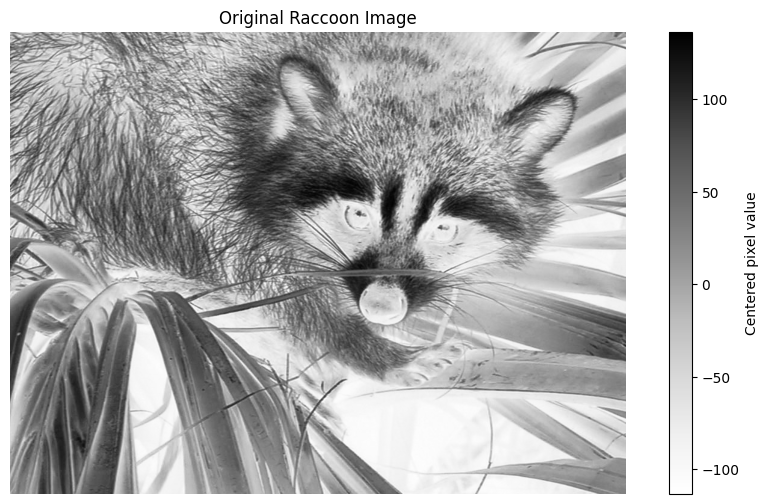

In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import datasets, signal

# Loading the grayscale raccoon image
face = datasets.face(gray=True).astype(float)

# Centering pixel values around their average
face = face - face.mean()

# Displaying the original image
plt.figure(figsize=(11, 6))
plt.imshow(face, cmap="Greys")
plt.title("Original Raccoon Image")
plt.colorbar(label="Centered pixel value")
plt.axis("off")
plt.show()



### Interpretation

The image is represented as a two-dimensional array of pixel values.

I converted the image to grayscale because this exercise focuses on brightness patterns rather than colors.

I then subtracted the mean pixel value. This centers the image data around zero and helps us compare differences in brightness.

The resulting image will be used for template matching and edge detection.


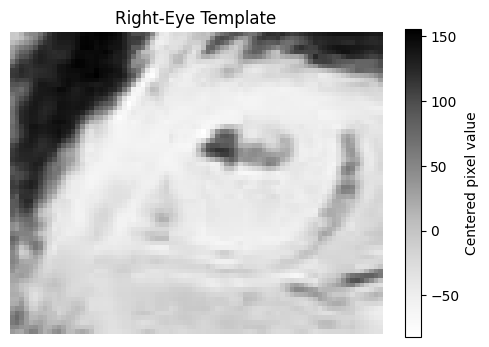

In [2]:

# Selecting the right-eye region from the original image
image_part = face[300:365, 670:750].copy()

# Centering the template before matching
image_part = image_part - image_part.mean()

# Displaying the selected eye template
plt.figure(figsize=(6, 4))
plt.imshow(image_part, cmap="Greys")
plt.title("Right-Eye Template")
plt.colorbar(label="Centered pixel value")
plt.axis("off")
plt.show()



### Extracting the Eye Template

I selected a small region around the raccoon's right eye.

The selected region contains different brightness patterns, including darker eye areas and lighter surrounding fur.

I also subtracted the template's mean to center its values.

I chose this region because I wanted to investigate whether similar patterns appear elsewhere in the image.

The next step is to move the template across the image and calculate a response at each location.


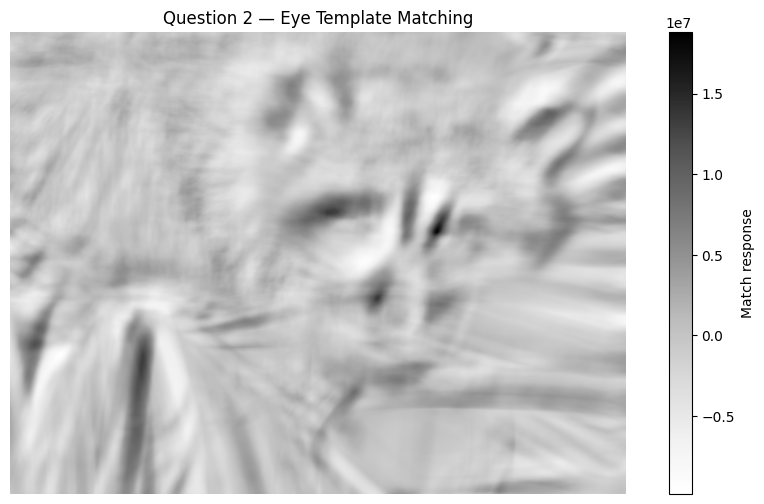

In [3]:

# Finding matching patterns across the raccoon image
match = signal.correlate2d(face, image_part, boundary="symm", mode="same")

# Displaying the matching responses
plt.figure(figsize=(11, 6))
plt.imshow(match, cmap="Greys")
plt.title("Question 2 — Eye Template Matching")
plt.colorbar(label="Match response")
plt.axis("off")
plt.show()



### Question 2 — Results and Interpretation

The output is a feature map showing how strongly the eye template matches different regions of the raccoon's face.

As expected, there is a strong response near the right eye because the template was taken from that location.

However, the left eye and nose also produce strong responses. These areas contain similar patterns, such as darker regions surrounded by lighter fur and contrasting edges.

This shows that cross-correlation detects local pixel patterns rather than identifying specific objects.

The operation does not understand what an eye or nose is. It simply calculates how closely the template matches nearby pixel values.

### Justification

I used `signal.correlate2d()` because it calculates the response between an image and a filter.

Setting `mode="same"` keeps the output dimensions equal to the original image.

Setting `boundary="symm"` uses reflected values when processing the image borders.



## Question 3 of 6 — Question 2b and Question 2c

### Question 2b

Is the supplied Sobel operator a horizontal or vertical edge detector? Why?

### Understanding Sobel Filters

A Sobel filter detects changes in brightness between neighboring pixels.

Large brightness changes often indicate boundaries between objects or image regions.

The supplied Sobel filter is:

$$
K_x=
\begin{bmatrix}
1 & 0 & -1\\
2 & 0 & -2\\
1 & 0 & -1
\end{bmatrix}
$$

The weights are positive on the left and negative on the right.

Therefore, the filter measures left-to-right brightness changes, which correspond to vertical edges.

I will first visualize the filter and then apply it to the raccoon image.


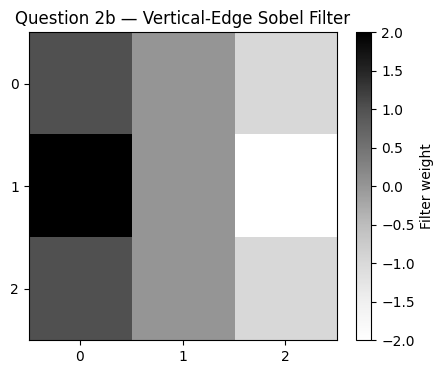

In [4]:

# Defining the vertical-edge Sobel filter
sobel_x = np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]])

# Displaying the filter weights
plt.figure(figsize=(5, 4))
plt.imshow(sobel_x, cmap="Greys")
plt.title("Question 2b — Vertical-Edge Sobel Filter")
plt.colorbar(label="Filter weight")
plt.xticks(range(3))
plt.yticks(range(3))
plt.show()


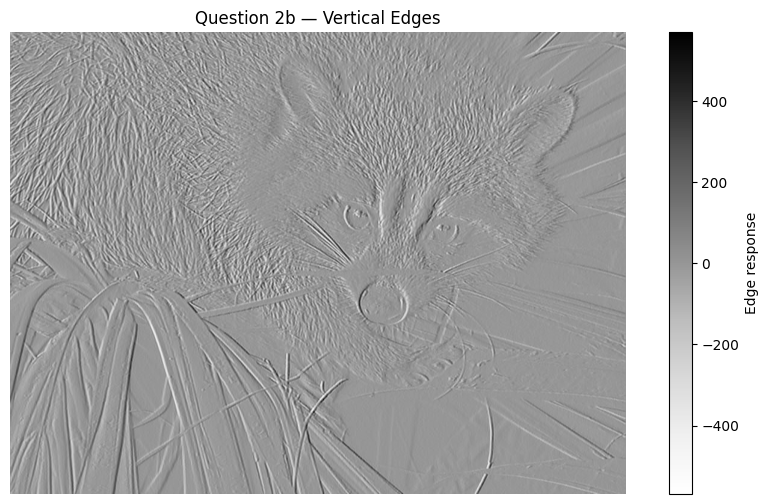

In [5]:

# Detecting left-to-right brightness changes
vertical_edges = signal.correlate2d(face, sobel_x, boundary="symm", mode="same")

# Displaying the detected vertical edges
plt.figure(figsize=(11, 6))
plt.imshow(vertical_edges, cmap="Greys")
plt.title("Question 2b — Vertical Edges")
plt.colorbar(label="Edge response")
plt.axis("off")
plt.show()



### Question 2b — Interpretation

The Sobel filter detects vertical edges because it measures changes in brightness from left to right.

For example, a bright region on the left and a dark region on the right produce a positive response.

The opposite arrangement produces a negative response.

When applied to the raccoon image, the filter highlights vertical boundaries around its eyes, ears, and fur.

This demonstrates how a simple matrix of weights can identify specific visual patterns.

### Question 2c — How Does Convolution Work with Color Images?

The previous example used grayscale images, which have only one channel.

A color image usually contains three channels: red, green, and blue (RGB).

A convolutional filter must cover all three input channels.

For example, a filter with a spatial size of 3 × 3 has dimensions:

$$
3 \times 3 \times 3
$$

At each location, the filter multiplies its weights by the corresponding pixel values.

The products are then added across all three channels.

For one output position:

$$
R(i,j)=b+\sum_{c=1}^{3}\sum_{u=0}^{2}\sum_{v=0}^{2}K(u,v,c)I(i+u,j+v,c)
$$

Here, $b$ represents the bias.

One filter produces one output feature map. Therefore, using 16 filters produces 16 output feature maps.

### Connection to CNNs

CNNs use multiple filters to detect different patterns at the same time.

Some filters can detect edges, while others may identify colors, textures, or shapes.

Deeper layers combine these patterns to form more complex visual representations.



## Question 4 of 6 — Extension Question: Sobel Operators and Gradients

### Question

Apply the other Sobel filter to the raccoon image.

What does the resulting image look like? How is it different from the filter used in Question 2?

### Approach

In Question 2, I applied a Sobel filter that detects vertical edges.

Now, I will apply the second Sobel filter, which detects horizontal edges.

The horizontal Sobel filter is:

$$
K_y=
\begin{bmatrix}
1 & 2 & 1\\
0 & 0 & 0\\
-1 & -2 & -1
\end{bmatrix}
$$

This filter measures changes in brightness from top to bottom.

I will apply both filters and compare their outputs.

My expectation is that they will highlight different boundaries in the same image.


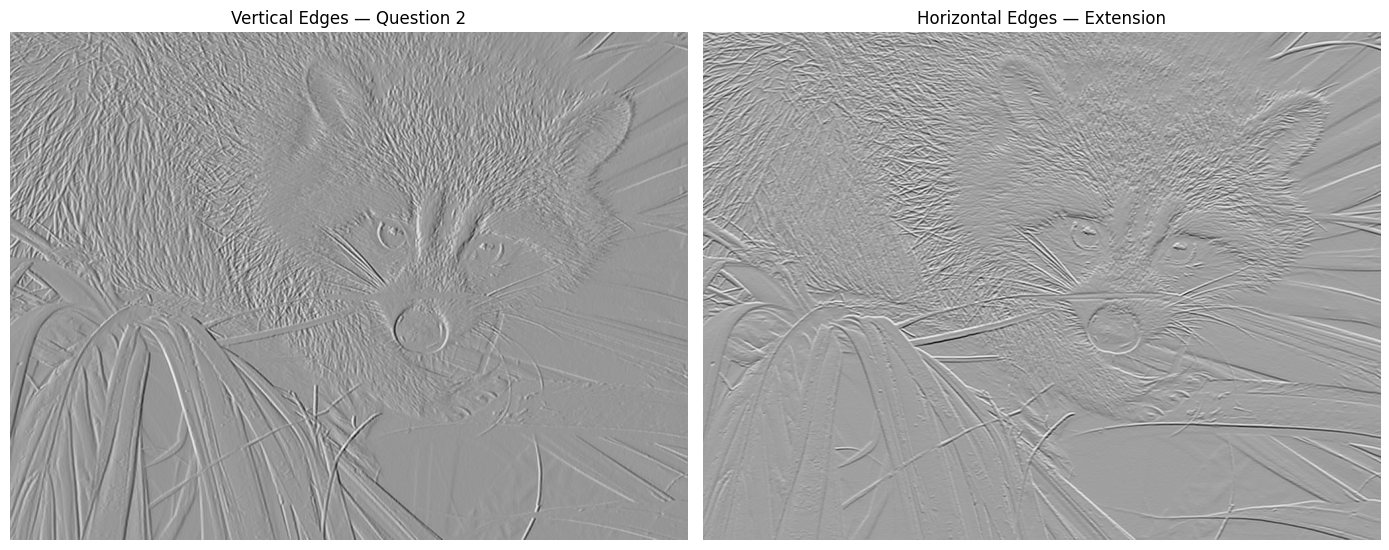

In [6]:

# Defining the horizontal-edge Sobel filter
sobel_y = np.array([[1, 2, 1], [0, 0, 0], [-1, -2, -1]])

# Applying both edge filters to the original image
vertical_edges = signal.correlate2d(face, sobel_x, boundary="symm", mode="same")
horizontal_edges = signal.correlate2d(face, sobel_y, boundary="symm", mode="same")

# Comparing the two filtered images
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].imshow(vertical_edges, cmap="Greys")
axes[0].set_title("Vertical Edges — Question 2")
axes[0].axis("off")

axes[1].imshow(horizontal_edges, cmap="Greys")
axes[1].set_title("Horizontal Edges — Extension")
axes[1].axis("off")

plt.tight_layout()
plt.show()



### Results and Interpretation

The horizontal Sobel filter highlights boundaries where brightness changes from top to bottom.

The resulting image shows horizontal structures around the raccoon's eyes, nose, ears, and surrounding leaves.

The two filters emphasize different directions.

The vertical filter detects left-to-right brightness changes, while the horizontal filter detects top-to-bottom changes.

Both use the same cross-correlation operation, but their weight arrangements are different.

### Justification

I applied both filters to compare how their orientation changes the resulting image.

This demonstrates that filters can detect different features without changing the original image.

By combining both responses, we should obtain a more complete representation of the image's boundaries.



## Question 5 of 6 — Combining the Sobel Gradients

### Question

Combine the vertical and horizontal Sobel outputs to calculate the image gradient.

What does the combined image look like, and how does it differ from either filter alone?

### Approach

The vertical and horizontal Sobel filters detect brightness changes in different directions.

I will combine their outputs to calculate the overall edge strength at each pixel.

The gradient magnitude is:

$$
G=\sqrt{G_x^2+G_y^2}
$$

Here:

- $G_x$ represents the horizontal brightness change detected by the vertical-edge filter.
- $G_y$ represents the vertical brightness change detected by the horizontal-edge filter.
- $G$ represents the total edge strength.

Squaring both responses removes negative signs. Adding them combines the two directions.

Finally, taking the square root gives the gradient magnitude.

I expect the combined image to highlight edges across different directions.


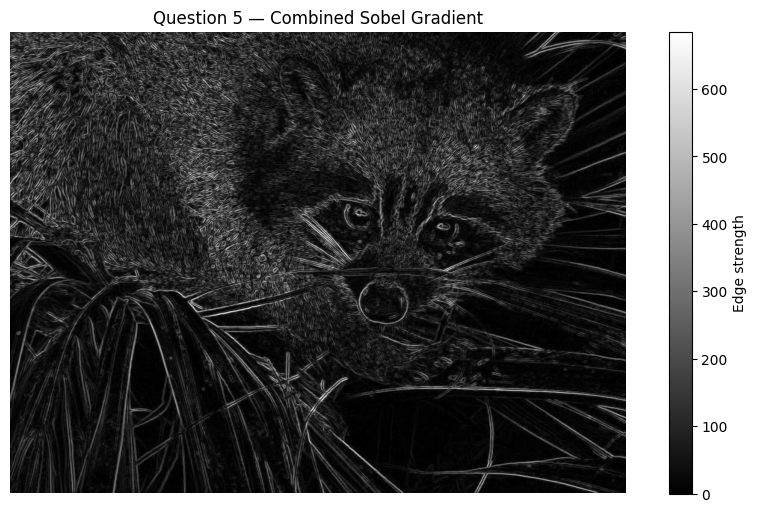

In [7]:

# Combining the vertical and horizontal edge responses
gradient = np.sqrt(vertical_edges**2 + horizontal_edges**2)

# Displaying the overall edge strength
plt.figure(figsize=(11, 6))
plt.imshow(gradient, cmap="gray")
plt.title("Question 5 — Combined Sobel Gradient")
plt.colorbar(label="Edge strength")
plt.axis("off")
plt.show()



### Results and Interpretation

The combined gradient produces a more complete outline of the raccoon.

Bright regions indicate strong changes in pixel brightness, while dark regions indicate relatively uniform areas.

The raccoon's eyes, nose, fur, and surrounding leaves become more visible through their boundaries.

Unlike the individual filters, the combined gradient captures edges across different directions, including diagonal edges.

### Justification

I combined both Sobel outputs because each filter only measures brightness changes along one direction.

Using the gradient magnitude gives a single measure of overall edge strength.

This produces a more complete representation of the image's boundaries.

### Connection to CNNs

CNNs also use filters to detect local features in images.

However, instead of relying only on manually defined filters, CNNs can learn the filter weights during training.

Earlier layers often detect simple patterns, while deeper layers combine those patterns into more complex representations.



## Final Reflection — Session 17

This session helped me understand convolution as a process of matching local image patterns.

In the first experiment, I used an eye template to identify similar regions across the raccoon's face. The template produced strong responses around the eyes and nose because these areas shared similar pixel patterns.

I then used Sobel filters to detect vertical and horizontal edges. These experiments showed how changing a filter's weights changes the visual information it captures.

Finally, I combined both Sobel responses to calculate the gradient magnitude. This produced a more complete representation of the raccoon's boundaries.

The most important connection to CNNs is that filters act as feature detectors. CNNs extend this idea by learning filter weights and combining the detected patterns across multiple layers.

The experiments also helped me understand why weight sharing is useful. A single filter can detect the same pattern in different image locations without learning separate weights for every position.

### Limitations

These experiments use fixed filters rather than training a CNN. Therefore, they demonstrate feature detection but do not measure classification accuracy.

The results also depend on the selected filter weights and image content.

### Conclusion

Overall, I learned how convolution, edge detection, and feature maps work together in image processing.

These concepts form the foundation of convolutional neural networks and explain how CNNs learn increasingly complex visual features.
